# Лабораторная 1. Среда, данные и первая сводка

Задание целиком: `labs/lab01/README.md` в репозитории курса.

Как работать с ноутбуком:
1. В первой ячейке впишите свой номер варианта.
2. Заполните ячейки с пометкой `TODO` по порядку. Подсказки в комментариях.
3. В конце выполните Run All с нуля, скачайте ноутбук и `results.zip`.

Ноутбук работает в Kaggle, Colab и локально. В Kaggle включите интернет: правая панель → Settings → Internet → On. Если интернет в Kaggle включить нельзя, работайте в Colab или локально.

## 0. Установка и загрузка данных

Ячейка определяет, где запущен ноутбук, находит или скачивает `get_data.py` из репозитория курса и загружает ваш вариант. Ничего в ней менять не нужно, кроме `VARIANT`.

In [ ]:
VARIANT = 9   # TODO: ваш порядковый номер в списке группы, например 7
DATA_SOURCE = None  # запасной путь: папка с архивами variant_NN.zip

import os
import sys
import inspect
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, "Впишите свой номер варианта: целое число от 1 до 22"
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab01/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError("Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                               "в остальных случаях проверьте подключение к сети.") from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("данные варианта:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

среда: colab | папка данных: /content/data
Вариант 09: Persian, Sphynx, american_bulldog, staffordshire_bull_terrier
  Скачиваю https://github.com/ykvnkm/computer-vision-course/releases/download/data-v1/variant_09.zip
  variant_09.zip: 86.9 МБ, готово.                              
  Распаковываю в /content/data/variant_09 ...
Готово: /content/data/variant_09 (797 изображений)
данные варианта: /content/data/variant_09
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [ ]:
import json
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image

IMG_DIR = DATA_DIR / "images"
XML_DIR = DATA_DIR / "annotations" / "xmls"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

print("OpenCV", cv2.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

OpenCV 5.0.0 | numpy 2.1.3 | pandas 2.2.3


## 1. Что лежит в папке варианта

Прочитайте `variant.json` и `labels.csv`. Проверьте, что номер варианта в `variant.json` совпадает с вашим.

In [ ]:
variant_path = DATA_DIR / "variant.json"
variant_info = json.loads(variant_path.read_text(encoding="utf-8"))

print("Информация о варианте:")
for key, value in variant_info.items():
    print(f"{key}: {value}")

labels_path = DATA_DIR / "labels.csv"
labels = pd.read_csv(labels_path)

print("\nПервые пять записей датасета:")
display(labels.head(5))

Информация о варианте:
variant: 9
dataset_version: v1
source: release
breeds: ['Persian', 'Sphynx', 'american_bulldog', 'staffordshire_bull_terrier']
species: {'Persian': 'cat', 'Sphynx': 'cat', 'american_bulldog': 'dog', 'staffordshire_bull_terrier': 'dog'}
class_ids: {'Persian': 0, 'Sphynx': 1, 'american_bulldog': 2, 'staffordshire_bull_terrier': 3}
names_ru: {'Persian': 'персидская кошка', 'Sphynx': 'сфинкс', 'american_bulldog': 'американский бульдог', 'staffordshire_bull_terrier': 'стаффордширский бультерьер'}
n_images: 797
n_boxes: 404
n_trimaps: 797
per_breed: {'Persian': {'images': 201, 'boxes': 100, 'trimaps': 201}, 'Sphynx': {'images': 202, 'boxes': 102, 'trimaps': 202}, 'american_bulldog': {'images': 202, 'boxes': 101, 'trimaps': 202}, 'staffordshire_bull_terrier': {'images': 192, 'boxes': 101, 'trimaps': 192}}
dataset: Oxford-IIIT Pet
dataset_url: https://www.robots.ox.ac.uk/~vgg/data/pets/
license: CC BY-SA 4.0
citation: O. M. Parkhi, A. Vedaldi, A. Zisserman, C. V. Jawahar

,filename,breed,species,class_id
0,american_bulldog_2.jpg,american_bulldog,dog,2
1,american_bulldog_3.jpg,american_bulldog,dog,2
2,american_bulldog_5.jpg,american_bulldog,dog,2
3,american_bulldog_6.jpg,american_bulldog,dog,2
4,american_bulldog_7.jpg,american_bulldog,dog,2


## 2. Изображение как массив

Возьмите одно изображение и посмотрите, что вернул OpenCV. Выберите файл, который Pillow определяет как `JPEG` в режиме `RGB`: необычные файлы разберём в разделе 3.

In [ ]:
# Выбираем самое «цветное» фото среди 100 случайных обычных JPEG: на нём ошибка BGR/RGB заметнее
best, best_score = None, -1.0
for fn in labels["filename"].sample(frac=1, random_state=0).head(100):
    with Image.open(IMG_DIR / fn) as im:
        if im.format != "JPEG" or im.mode != "RGB":
            continue
        arr = np.asarray(im.resize((64, 64)), dtype=np.float32)[16:48, 16:48]  # центр кадра
    score = float(np.abs(arr[..., 0] - arr[..., 2]).mean())
    if score > best_score:
        best, best_score = fn, score
example_name = best
example_path = IMG_DIR / example_name
print(example_name)

bgr = cv2.imread(str(example_path))

print("Тип объекта:", type(bgr))
print("Размер изображения:", bgr.shape)
print("Тип данных:", bgr.dtype)
print("Минимальное значение:", bgr.min())
print("Максимальное значение:", bgr.max())
print("Центральный пиксель:", bgr[bgr.shape[0] // 2, bgr.shape[1] // 2])

Persian_115.jpg
Тип объекта: <class 'numpy.ndarray'>
Размер изображения: (375, 500, 3)
Тип данных: uint8
Минимальное значение: 0
Максимальное значение: 255
Центральный пиксель: [ 91 150 222]


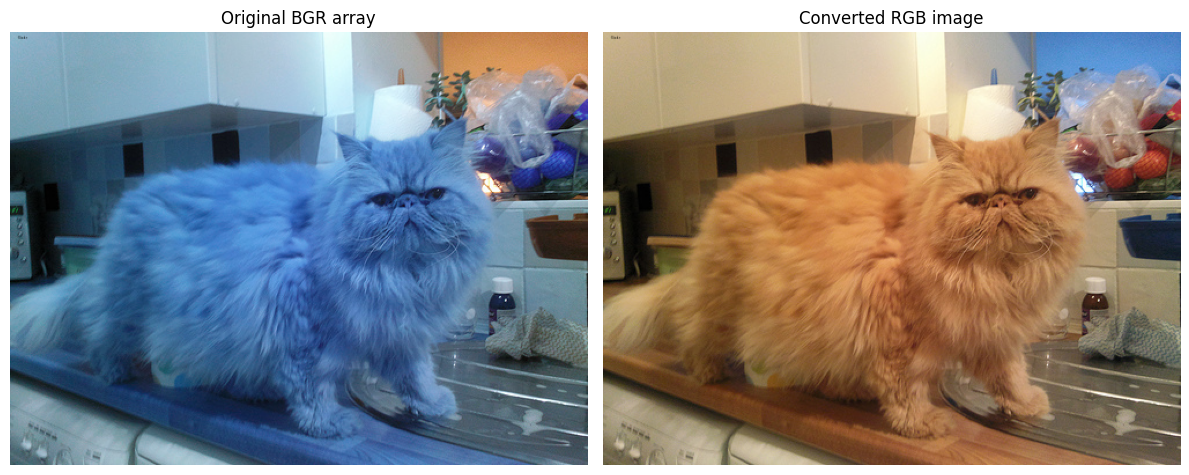

In [ ]:
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(bgr)
plt.title("Original BGR array")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rgb)
plt.title("Converted RGB image")
plt.axis("off")

plt.tight_layout()
plt.show()

Преобразования. Подсказки:

| Что | Функция |
|---|---|
| оттенки серого | `cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)` |
| ресайз | `cv2.resize(rgb, (224, 224))` |
| отражение | `cv2.flip(rgb, 1)` |

In [ ]:
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
resized = cv2.resize(rgb, (224, 224))
flipped = cv2.flip(rgb, 1)

print("Grayscale:", gray.shape)
print("Resized:", resized.shape)
print("Flipped:", flipped.shape)

Grayscale: (375, 500)
Resized: (224, 224, 3)
Flipped: (375, 500, 3)


In [ ]:
# Ловушка uint8: запустите и посмотрите, что получилось
a = np.array([[50, 200, 250]], dtype=np.uint8)   # «картинка» 1x3 пикселя
print("numpy a + 100:", a + 100)
print("cv2.add:      ", cv2.add(a, np.full_like(a, 100)))

numpy a + 100: [[150  44  94]]
cv2.add:       [[150 255 255]]


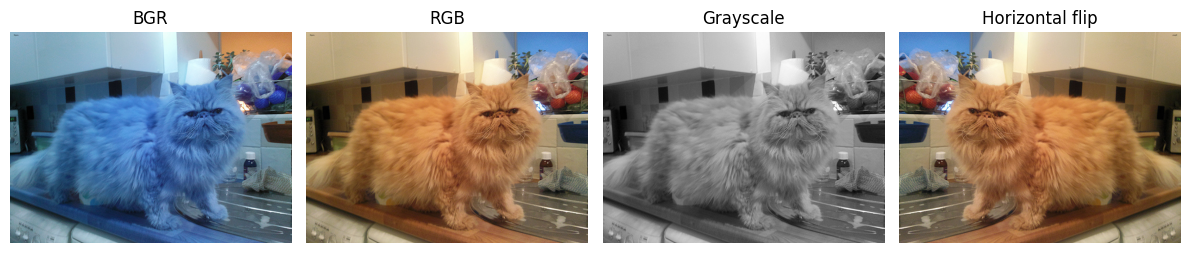

In [ ]:
plt.figure(figsize=(12, 3))

images = [
    (bgr, "BGR", None),
    (rgb, "RGB", None),
    (gray, "Grayscale", "gray"),
    (flipped, "Horizontal flip", None)
]

for i, (image, title, color_map) in enumerate(images, start=1):
    plt.subplot(1, 4, i)
    plt.imshow(image, cmap=color_map)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.savefig(RESULTS / "transforms.png", dpi=110)
plt.show()

## 3. Сводка по датасету

Пройдите по всем файлам в `images/`. Для каждого соберите словарь и добавьте в список `rows`.

`Image.open(p)` из Pillow честно говорит формат (`.format`) и режим (`.mode`: `RGB`, `L`, `RGBA`, `P`). `cv2.imread(p)` по умолчанию всегда отдаёт 3 канала и такие файлы не выдаст.

In [ ]:
label_by_file = labels.set_index("filename")

rows = []
for p in sorted(IMG_DIR.iterdir()):
    if p.name.startswith("."):
        continue
    rec = {"filename": p.name, "ext": p.suffix.lower()}

    with Image.open(p) as im:
        rec["pil_format"] = im.format
        rec["mode"] = im.mode
        rec["width"] = im.width
        rec["height"] = im.height

    rec["has_xml"] = (XML_DIR / (p.stem + ".xml")).is_file()

    if p.name in label_by_file.index:
        rec["breed"] = label_by_file.loc[p.name, "breed"]
        rec["species"] = label_by_file.loc[p.name, "species"]
    else:
        rec["breed"] = None
        rec["species"] = None

    rows.append(rec)

info = pd.DataFrame(rows)
display(info.head())

,filename,ext,pil_format,mode,width,height,has_xml,breed,species
0,Persian_1.jpg,.jpg,JPEG,RGB,275,196,True,Persian,cat
1,Persian_10.jpg,.jpg,JPEG,RGB,375,500,True,Persian,cat
2,Persian_100.jpg,.jpg,JPEG,RGB,500,334,True,Persian,cat
3,Persian_101.jpg,.jpg,JPEG,RGB,377,500,True,Persian,cat
4,Persian_102.jpg,.jpg,JPEG,RGB,376,500,True,Persian,cat


In [ ]:
summary = {
    "variant": VARIANT,
    "n_files": len(info),
    "n_breeds": info["breed"].nunique(),
    "n_cats": (info["species"].str.lower() == "cat").sum(),
    "n_dogs": (info["species"].str.lower() == "dog").sum(),
    "width_min": info["width"].min(),
    "width_median": info["width"].median(),
    "width_max": info["width"].max(),
    "height_min": info["height"].min(),
    "height_median": info["height"].median(),
    "height_max": info["height"].max(),
    "n_non_rgb": (info["mode"] != "RGB").sum(),
    "n_jpg_not_jpeg": ((info["ext"] == ".jpg") & (info["pil_format"] != "JPEG")).sum(),
    "n_with_xml": info["has_xml"].sum()
}

summary_df = pd.DataFrame(list(summary.items()), columns=["metric", "value"])
summary_df.to_csv(RESULTS / "summary.csv", index=False)
display(summary_df)

,metric,value
0,variant,9.0
1,n_files,797.0
2,n_breeds,4.0
3,n_cats,403.0
4,n_dogs,394.0
5,width_min,161.0
6,width_median,500.0
7,width_max,1280.0
8,height_min,168.0
9,height_median,375.0


### Проблемные файлы

Найдите файлы, которые сломают обучение в следующих лабах: режим не `RGB` или формат не совпадает с расширением. Для одного такого файла сравните `cv2.imread(p).shape` и `cv2.imread(p, cv2.IMREAD_UNCHANGED).shape`.

In [ ]:
non_rgb_files = info.loc[info["mode"] != "RGB", ["filename", "mode"]]
non_jpeg_files = info.loc[info["pil_format"] != "JPEG", ["filename", "pil_format"]]

print("Файлы, у которых mode отличается от RGB:")
display(non_rgb_files)

print("Файлы, у которых формат отличается от JPEG:")
display(non_jpeg_files)

Файлы, у которых mode отличается от RGB:


,filename,mode
706,staffordshire_bull_terrier_2.jpg,L
712,staffordshire_bull_terrier_22.jpg,L


Файлы, у которых формат отличается от JPEG:


,filename,pil_format


In [ ]:
problem_files = info.loc[info["mode"] != "RGB", "filename"]

if not problem_files.empty:
    problem_path = IMG_DIR / problem_files.iloc[0]
    default_img = cv2.imread(str(problem_path))
    unchanged_img = cv2.imread(str(problem_path), cv2.IMREAD_UNCHANGED)

    print("Файл:", problem_path.name)
    print("Обычное чтение:", default_img.shape if default_img is not None else None)
    print("IMREAD_UNCHANGED:", unchanged_img.shape if unchanged_img is not None else None)
else:
    print("Изображений с режимом, отличным от RGB, не найдено.")

Файл: staffordshire_bull_terrier_2.jpg
Обычное чтение: (282, 500, 3)
IMREAD_UNCHANGED: (282, 500)


## 4. Разметка и сетка примеров

- XML в формате Pascal VOC: внутри `<object><bndbox>` координаты `xmin, ymin, xmax, ymax`. Есть не у всех изображений, иногда объектов два.
- Trimap: PNG того же размера, что и фото. 1 = животное, 2 = фон, 3 = граница.

In [ ]:
def read_boxes(xml_path):
    # Все боксы из XML: список (xmin, ymin, xmax, ymax)
    root = ET.parse(xml_path).getroot()
    return [tuple(int(float(bb.find(k).text)) for k in ("xmin", "ymin", "xmax", "ymax"))
            for bb in root.iter("bndbox")]

annotated = info.loc[info["has_xml"] == True, "filename"]

if not annotated.empty:
    sample_name = annotated.iloc[0]
    stem = Path(sample_name).stem
    xml_path = XML_DIR / f"{stem}.xml"

    boxes = read_boxes(xml_path)
    print("Изображение:", sample_name)
    print("Bounding boxes:", boxes)

    trimap_path = TRIMAP_DIR / f"{stem}.png"
    trimap = cv2.imread(str(trimap_path), cv2.IMREAD_UNCHANGED)

    if trimap is not None:
        print("Уникальные значения trimap:", np.unique(trimap))
    else:
        print("Trimap не найден:", trimap_path)
else:
    print("Изображений с XML-аннотациями не найдено.")

Изображение: Persian_1.jpg
Bounding boxes: [(42, 22, 115, 84)]
Уникальные значения trimap: [1 2 3]


Сетка: по одному фото каждой породы с боксом головы. Бокс рисуется так: `cv2.rectangle(rgb, (x0, y0), (x1, y1), (0, 255, 0), 3)`. Берите фото, у которых есть XML.

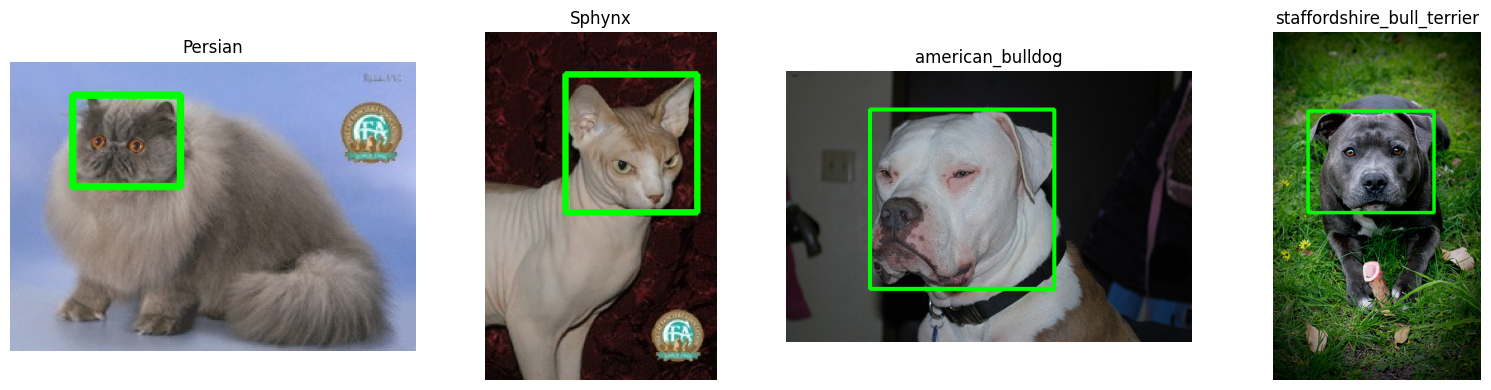

In [ ]:
breed_samples = info.loc[info["has_xml"]].groupby("breed", sort=True).first().reset_index()

fig, axes = plt.subplots(1, len(breed_samples), figsize=(4 * len(breed_samples), 4))

if len(breed_samples) == 1:
    axes = [axes]

for ax, (_, sample) in zip(axes, breed_samples.iterrows()):
    image_path = IMG_DIR / sample["filename"]
    xml_path = XML_DIR / f"{Path(sample['filename']).stem}.xml"

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    for xmin, ymin, xmax, ymax in read_boxes(xml_path):
        cv2.rectangle(image, (xmin, ymin), (xmax, ymax), (0, 255, 0), 3)

    ax.imshow(image)
    ax.set_title(str(sample["breed"]))
    ax.axis("off")

plt.tight_layout()
plt.savefig(RESULTS / "samples_grid.png", dpi=110, bbox_inches="tight")
plt.show()

## 5. Числа для отчёта и выгрузка

Напечатайте всё, что понадобится в README. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab01/`.

Переименуйте скачанный ноутбук в `solution.ipynb`.

In [ ]:
print(summary_df.to_string(index=False))

expected = {"summary.csv", "transforms.png", "samples_grid.png"}
missing = expected - {p.name for p in RESULTS.iterdir()}
print("не хватает:", missing if missing else "ничего, все 3 файла на месте")

        metric  value
       variant    9.0
       n_files  797.0
      n_breeds    4.0
        n_cats  403.0
        n_dogs  394.0
     width_min  161.0
  width_median  500.0
     width_max 1280.0
    height_min  168.0
 height_median  375.0
    height_max 1024.0
     n_non_rgb    2.0
n_jpg_not_jpeg    0.0
    n_with_xml  404.0
не хватает: ничего, все 3 файла на месте


In [ ]:
import shutil
if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files
        files.download(archive)

архив: /content/results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>